# Bump hunt: inference with the released RACNN-ClassiFlow ensemble

This notebook reproduces the paper's Fig 3 with the released RACNN-ClassiFlow ensemble (3 of 5 runs, `weights/ensembles.json`). For a signal hypothesis $\theta = (\theta_m, \theta_s)$ and a signal region (SR) $c = [x_\mathrm{lo}, x_\mathrm{hi}]$, it simulates one dataset with `bump_hunt.py` and shows

* the histograms in the SR: signal + background, background, and signal;
* the ensemble posterior $p(\theta_m, \theta_s \mid \mathcal{D}_c, c)$ on the signal-plus-background ensemble, and on the background-only ensemble;
* the classifier output $P(s+b \mid \mathcal{D}_c, c)$, the logit $\Lambda$ and the posterior entropy $H$.

It runs on a CPU in about a minute.

**Before running:** download the data with `python scripts/download.py --no-train` from the repository root (the weights are already in `weights/`).

In [14]:
import os, sys, json
import numpy as np
import torch
import matplotlib.pyplot as plt

REPO    = os.path.abspath("..")               # repository root (this notebook lives in bumphunt/)
DATA    = os.path.join(REPO, "data")          # datasets from Hugging Face, see scripts/download.py
WEIGHTS = os.path.join(REPO, "weights")       # trained weights, part of this repository
sys.path.insert(0, REPO)
import racnn_inference as ri

_, fd = ri.import_analysis("bumphunt")           # puts bumphunt/ on sys.path; fd = flexibledataset
import inference_plots as ip
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

No GPU available. Using CPU.
device: cpu


In [15]:
ensemble = ri.load_ensemble("bumphunt", "racnnclassiflows", "best_model", WEIGHTS, device)
print("ensemble runs:", json.load(open(f"{WEIGHTS}/ensembles.json"))["bumphunt"]["racnnclassiflows"]["best_model"])
scalers = fd.load_h5(f"{DATA}/bumphunt/test.h5", index=[0])   # only its normalisation (scalers) is used

sub-manifold (0 - e2 - gggt) and intra-manifold flow (0 - g) options overwrite  upper_bound_for_widths  with  1
sub-manifold (0 - e2 - gggt) and intra-manifold flow (0 - g) options overwrite  lower_bound_for_widths  with  0.01
sub-manifold (0 - e2 - gggt) and intra-manifold flow (0 - g) options overwrite  fit_normalization  with  0
sub-manifold (0 - e2 - gggt) and intra-manifold flow (1 - g) options overwrite  upper_bound_for_widths  with  1
sub-manifold (0 - e2 - gggt) and intra-manifold flow (1 - g) options overwrite  lower_bound_for_widths  with  0.01
sub-manifold (0 - e2 - gggt) and intra-manifold flow (1 - g) options overwrite  fit_normalization  with  0
sub-manifold (0 - e2 - gggt) and intra-manifold flow (2 - g) options overwrite  upper_bound_for_widths  with  1
sub-manifold (0 - e2 - gggt) and intra-manifold flow (2 - g) options overwrite  lower_bound_for_widths  with  0.01
sub-manifold (0 - e2 - gggt) and intra-manifold flow (2 - g) options overwrite  fit_normalization  with  

## Paper Fig 3

Two examples: a wide window $c = [2, 28]$ that contains the whole bump at $\theta = (10, 3)$, and a narrow window $c = [12.5, 18.5]$ that only catches the tail of a bump at $\theta = (4, 4.5)$. Each run simulates a new dataset, so the counts, P(s+b) and H differ slightly from the paper figure; fix the seed for a reproducible example.

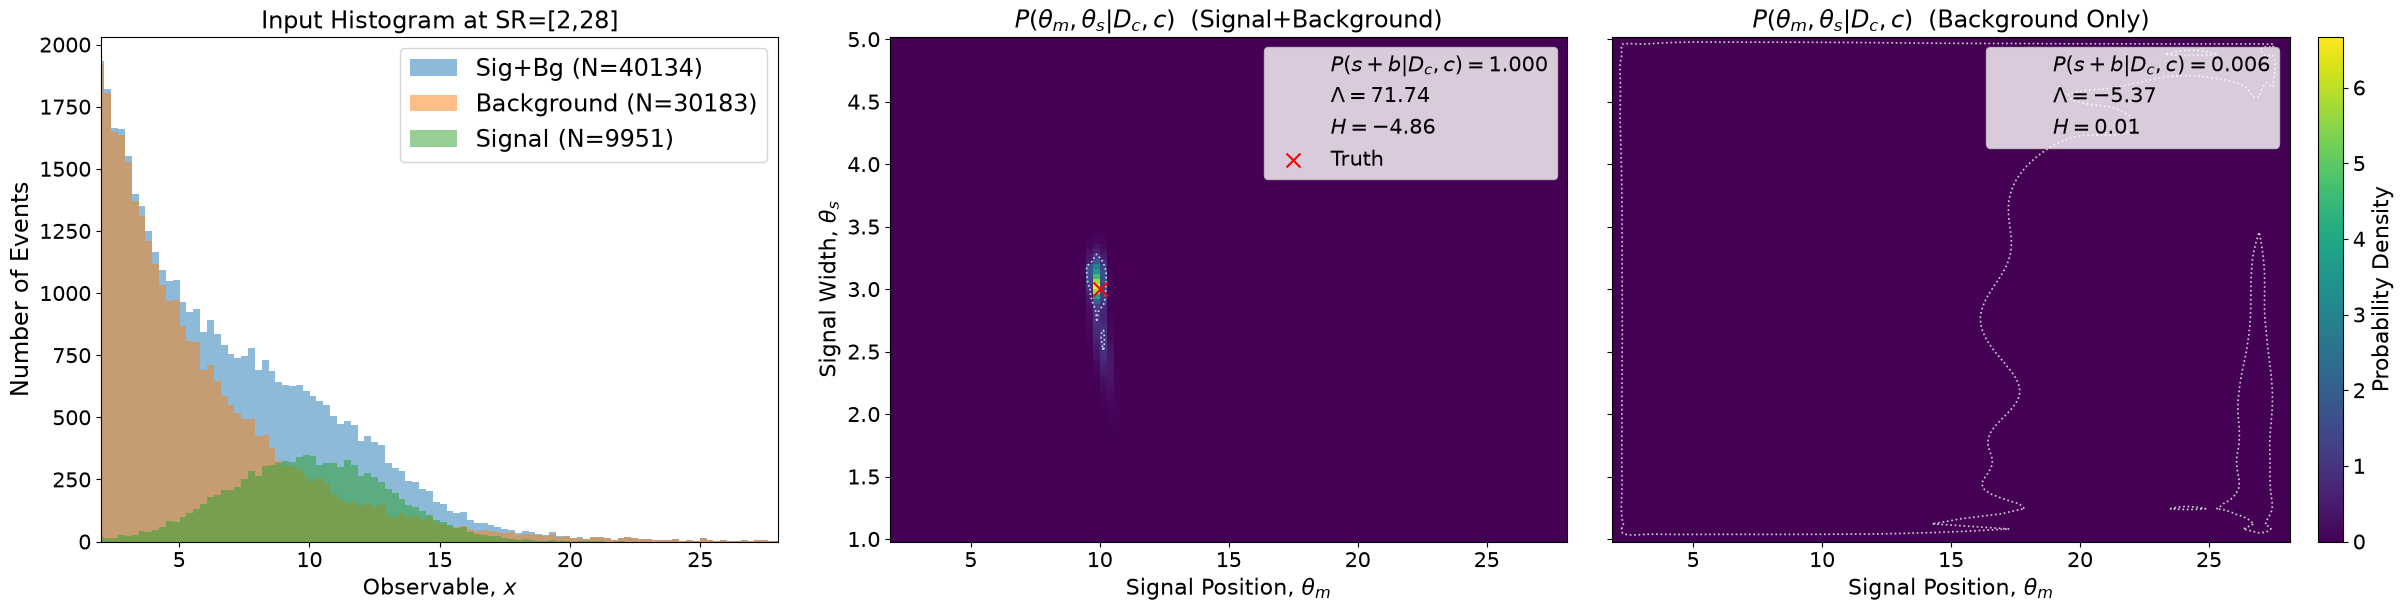

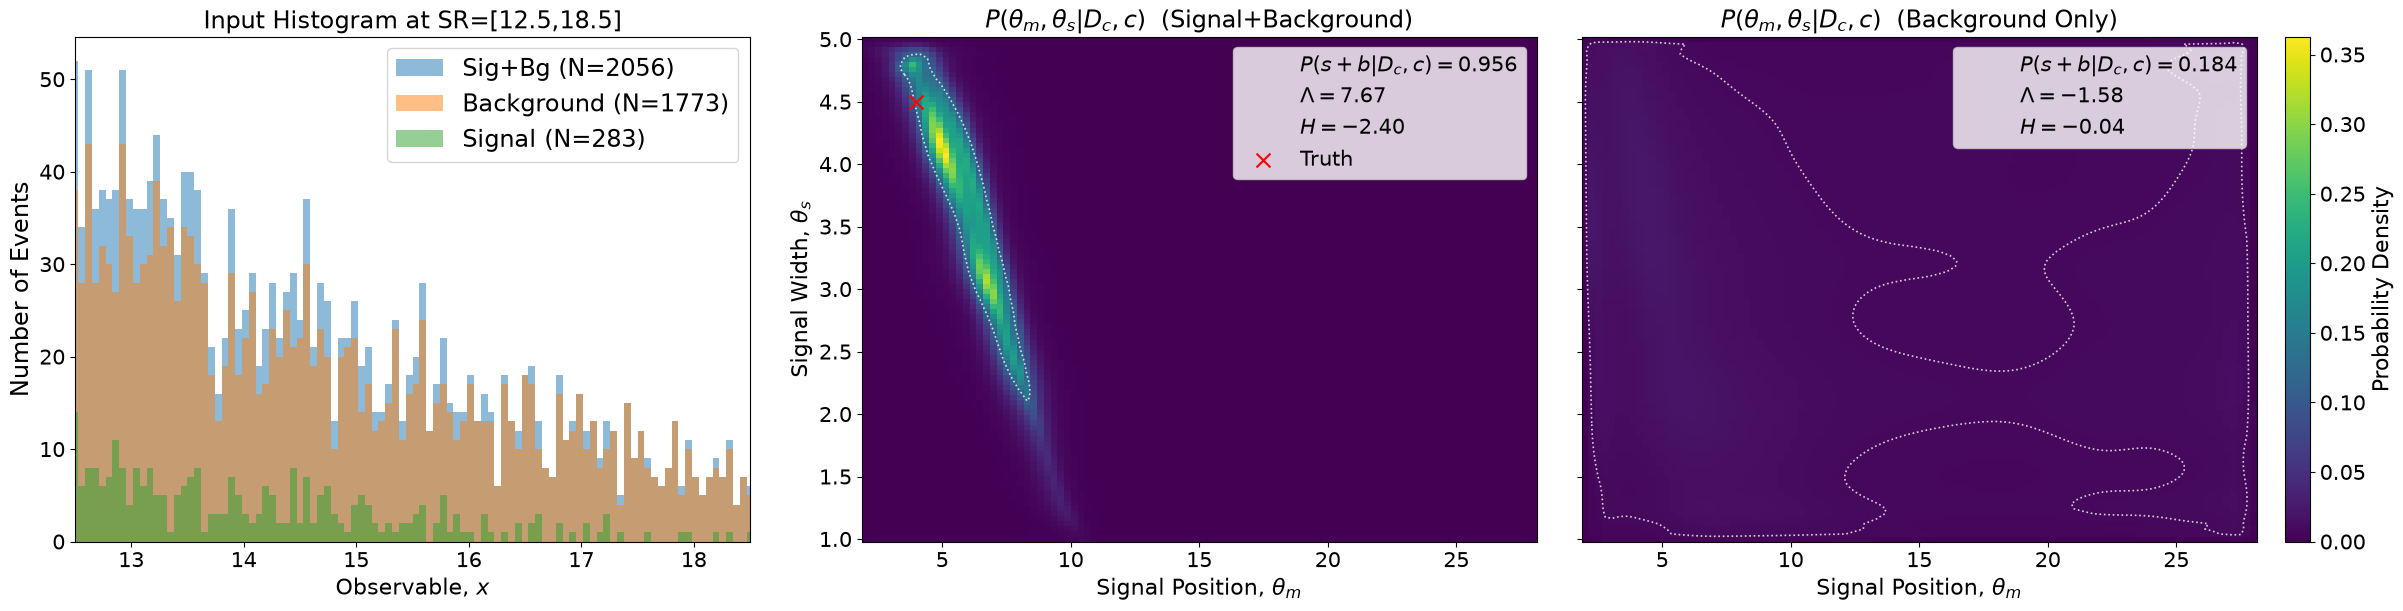

In [16]:
FIG3 = [(10, 3, 2, 28), (4, 4.5, 12.5, 18.5)]          # (theta_m, theta_s, x_lo, x_hi)
for n, (theta_m, theta_s, x_lo, x_hi) in enumerate(FIG3, start=1):
    np.random.seed(1234 + n); torch.manual_seed(1234 + n)
    ip.generate_exact_inference_plot_paper_ready(theta_m, theta_s, x_lo, x_hi, ensemble, scalers,
                                                 grid_bins=100, mu_range=(2, 28), sigma_range=(1, 5), device=device)
    plt.show()

## Your own example

Any $\theta_m \in [2, 28]$, $\theta_s \in [1, 5]$, and a window inside $[0, 30]$ at least 2.5 wide.

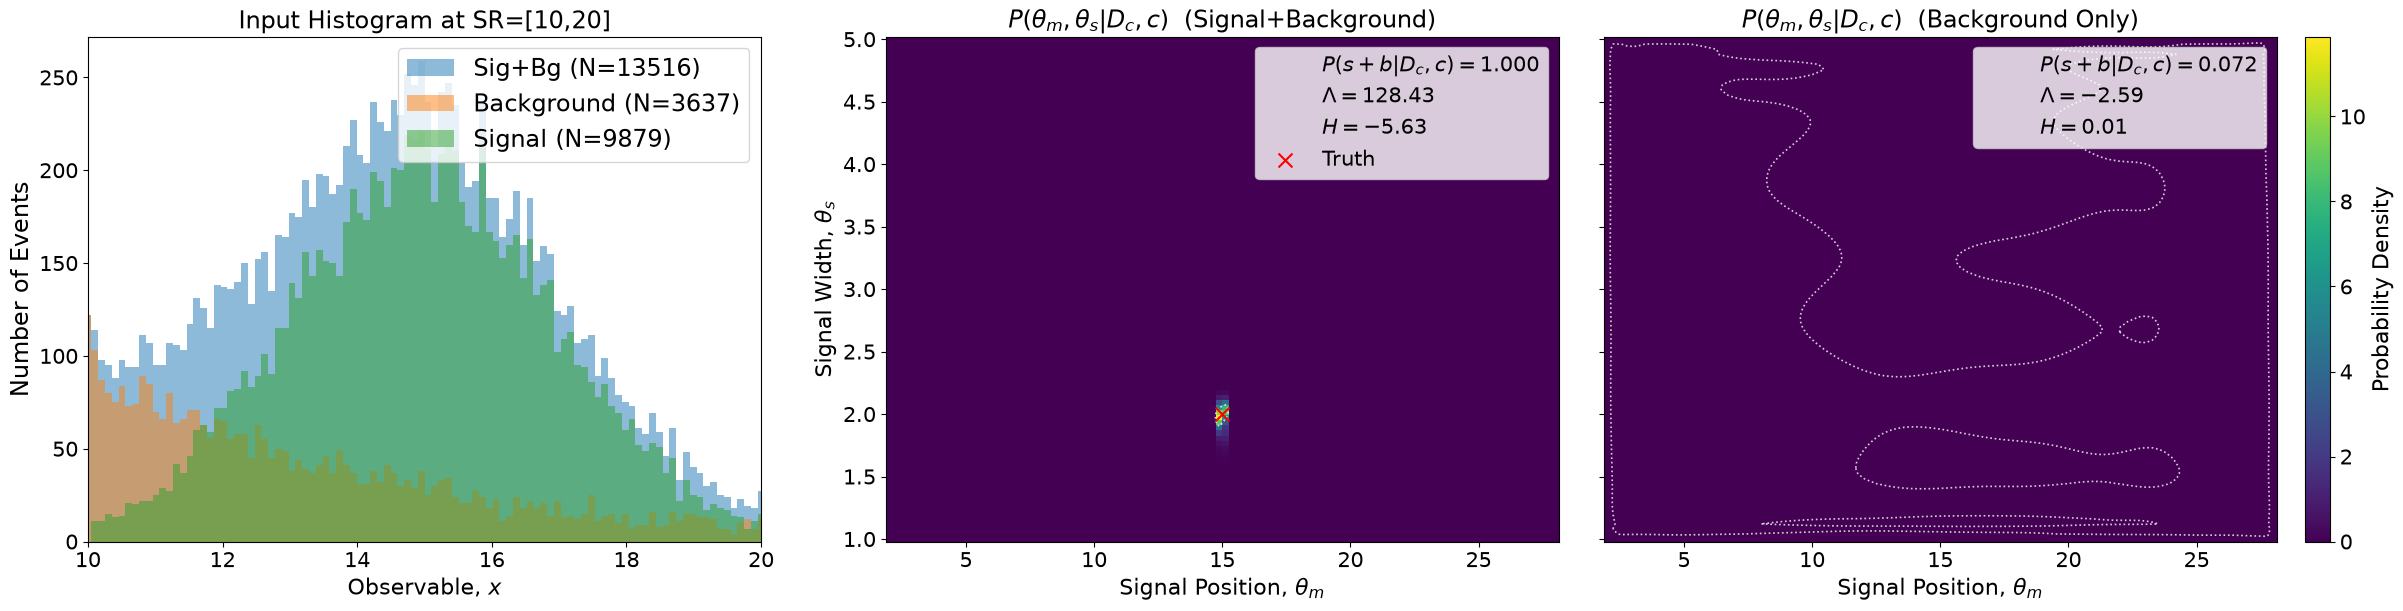

In [17]:
theta_m, theta_s, x_lo, x_hi = 15, 2, 10, 20
np.random.seed(0)
ip.generate_exact_inference_plot_paper_ready(theta_m, theta_s, x_lo, x_hi, ensemble, scalers, grid_bins=100, device=device)
plt.show()